# CSE558 End-term, group DSC 10 (2 of 2): run the frozen forecaster

Loads the three frozen LightGBM boosters and their exact input matrix, adds the TabPFN-TS forecast, and rebuilds the submitted
forecast file. No training, no server, no feature pipeline: about 10 seconds on a laptop or on Colab.

**Formula** (log1p space, closed hub-days exactly 0):
$$\hat y = \exp\Big(0.8\cdot\tfrac13\textstyle\sum_{s}\log(1+\hat y^{\,\mathrm{hp17}}_s) + 0.2\cdot\log(1+\hat y^{\,\mathrm{TabPFN\text{-}TS\,mix}})\Big)-1$$
with seeds $s \in \{20260807, 20260808, 20260809\}$; the TabPFN-TS input is the equal log mix of its 365- and 730-day
contexts, so each context carries 0.10 of the final log forecast and each LightGBM seed about 0.267.

| File | What it is |
|---|---|
| `final/models/lightgbm_s*.txt.gz` | the three boosters (`hp17`: 255 leaves, feature fraction 0.15, min child 160, L2 24.1, lr 0.025, 1000 trees) |
| `final/forecast_matrix_open.parquet` | their input: the 40,282 open hub-days of the forecast window x 342 columns (+ Id) |
| `artifacts/test_window/tabpfn_mix_test.csv` | TabPFN-TS forecast (computed on a GPU; deterministic) |
| `final/submission_final.csv` | the frozen forecast file this notebook must reproduce |

In [1]:
# Setup: inside the repository, on a fresh machine or on Colab (then it clones only what is needed, about 200 MB)
import os, subprocess, sys
from pathlib import Path

def find_root():
    here = Path.cwd()
    for c in (here, here.parent, here / '3_endsem', here / 'ShadowDsc10-ShadowHub' / '3_endsem'):
        if (c / 'final' / 'final_manifest.json').exists():
            return c.resolve()
    return None

ROOT = find_root()
if ROOT is None:
    subprocess.run(['git', 'clone', '--depth', '1', '--filter=blob:none', '--sparse', 'https://github.com/kushiiitd05/ShadowDsc10-ShadowHub.git'], check=True)
    subprocess.run(['git', '-C', 'ShadowDsc10-ShadowHub', 'sparse-checkout', 'set', '3_endsem', '1_midterm/data/raw'], check=True)
    ROOT = find_root()
for module in ('pandas', 'pyarrow', 'lightgbm', 'matplotlib'):
    try:
        __import__(module)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', module], check=True)
os.chdir(ROOT)
sys.path[:0] = [str(ROOT / 'code'), str(ROOT / 'code' / 'model')]
print('found the 3_endsem folder; running from it')

found the 3_endsem folder; running from it


In [2]:
import numpy as np, pandas as pd, lightgbm
import predict_frozen as pf
print('lightgbm', lightgbm.__version__)
x_open = pd.read_parquet(ROOT / 'final' / 'forecast_matrix_open.parquet')
print('input matrix', x_open.shape, '(Id + feature columns); first columns:', list(x_open.columns[1:6]))

lightgbm 4.7.0
input matrix (40282, 343) (Id + feature columns); first columns: ['HubID', 'Weekday', 'IsOpen', 'PromoActive', 'RegionalHoliday']


## 1. Each frozen booster reproduces its saved forecast

In [3]:
table, seeds = pf.frozen_forecast(ROOT)
for s, p in seeds.items():
    saved = np.load(ROOT / 'final' / f'test_pred_lightgbm_s{s}.npy')
    print(f'seed {s}: max |log1p difference| vs the saved forecast = {np.max(np.abs(np.log1p(p) - np.log1p(saved))):.1e}')

seed 20260807: max |log1p difference| vs the saved forecast = 0.0e+00
seed 20260808: max |log1p difference| vs the saved forecast = 0.0e+00
seed 20260809: max |log1p difference| vs the saved forecast = 0.0e+00


## 2. The blend reproduces the submitted file

In [4]:
frozen = pd.read_csv(ROOT / 'final' / 'submission_final.csv')
same_ids = bool((table.Id.values == frozen.Id.values).all())
diff = float(np.max(np.abs(np.log1p(table.OrderVolume) - np.log1p(frozen.OrderVolume))))
print('rows', len(table), '| same Id order:', same_ids, '| max |log1p difference|:', diff)
assert same_ids and diff < 1e-9
table.head()

rows 46830 | same Id order: True | max |log1p difference|: 0.0


,Id,OrderVolume
0,1,4301.868656
1,2,2693.211157
2,3,4270.942128
3,4,9465.341069
4,5,1980.348236


## 3. What the forecast looks like: three hubs, last 120 days of history and the 42 forecast days

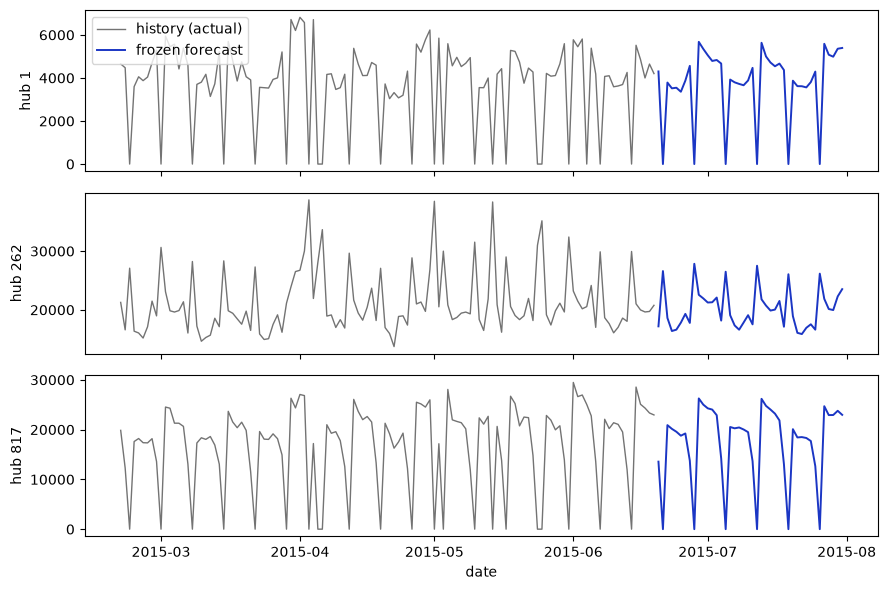

In [5]:
import matplotlib.pyplot as plt
raw = ROOT.parent / '1_midterm' / 'data' / 'raw'
hist = pd.read_csv(raw / 'orders_train.csv', usecols=['HubID', 'Date', 'OrderVolume'], parse_dates=['Date'])
frame = pd.read_csv(raw / 'orders_test.csv', usecols=['Id', 'HubID', 'Date'], parse_dates=['Date']).merge(table, on='Id')
fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True)
for ax, hub in zip(axes, (1, 262, 817)):
    h = hist[(hist.HubID == hub) & (hist.Date > hist.Date.max() - pd.Timedelta(days=120))]
    f = frame[frame.HubID == hub]
    ax.plot(h.Date, h.OrderVolume, color='0.45', lw=1, label='history (actual)')
    ax.plot(f.Date, f.OrderVolume, color='#1B36C4', lw=1.4, label='frozen forecast')
    ax.set_ylabel(f'hub {hub}')
axes[0].legend(loc='upper left'); axes[-1].set_xlabel('date')
plt.tight_layout(); plt.show()

Closed days are exactly 0 in the forecast. The forecast window has no labels in this project, so there is no score for it:
the model's quality is measured on the development folds (notebook 1, section 8).